# Load packages and params

In [45]:
import gc
import pickle
import shutil
import subprocess
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat, savemat
from probeinterface import Probe
import spikeinterface as si
import spikeinterface.preprocessing as spre
import spikeinterface.extractors as se
import spikeinterface.sorters as ss
import spikeinterface.curation as scur
from spikeinterface.sortingcomponents.motion import interpolate_motion
from spikeinterface.curation import compute_merge_unit_groups
from spikeinterface.exporters import export_to_phy
from spikeinterface.widgets import plot_motion_info
from tqdm import tqdm

import RCP_analysis as rcp
from RCP_analysis.python.functions.config_loading import *

# Setup
GEOM_PATH = rcp.resolve_probe_geom_path(PARAMS, REPO_ROOT, session_key=None)
NPRW_CFG = PARAMS.probes.get("NPRW")
INTAN_STREAM = NPRW_CFG.get("neural_data_stream")
STIM_STREAM = NPRW_CFG.get("stim_data_stream")
RADII = (NPRW_CFG.get("local_radius_inner"), NPRW_CFG.get("local_radius_outer"))
RATES = PARAMS.NPRW_rate_est
ARTRMV_MS_BEFORE = float(RATES.get("remove_ms_before", 20.0))
ARTRMV_TAIL_MS = float(RATES.get("remove_tail_ms_after", 20.0))

global_job_kwargs = dict(n_jobs=PARAMS.parallel_jobs, chunk_duration=PARAMS.chunk, progress_bar=True)
si.set_global_job_kwargs(**global_job_kwargs)

BLANKED_DIR = OUT_BASE / "checkpoints" / "NPRW_blanked_sessions"
BLANKED_DIR.mkdir(parents=True, exist_ok=True)

n_channels = 128
fs = 30000.0

# Load probe geometry
mat_probe = loadmat(Path(GEOM_PATH))
intan_geom = {"x": mat_probe["xcoords"].ravel(), "y": mat_probe["ycoords"].ravel()}
assert intan_geom["x"].size == intan_geom["y"].size
if "chanMap0ind" not in mat_probe:
    raise ValueError("No 0-based chanmap in .mat geometry file.")
intan_probe_mapping = mat_probe["chanMap0ind"].ravel()
if intan_probe_mapping.size != intan_geom["x"].size:
    raise ValueError("device_index_0based length != #contacts")

nprw_probe = Probe(ndim=2)
nprw_probe.set_contacts(
    positions=np.c_[intan_geom["x"], intan_geom["y"]],
    shapes="square", shape_params={"width": 12.0},
)
nprw_probe.set_device_channel_indices(intan_probe_mapping)

def blank_session(rec, stim_arrays, fs, ms_before, tail_ms):
    """Zero out stim artifact windows using this session's own local trigger indices."""
    block_bounds = stim_arrays.get("block_bounds_samples")
    starts = block_bounds[:, 0]
    ends = block_bounds[:, 1]
    n_total = rec.get_num_samples()

    valid = (ends > starts) & (starts >= 0) & (starts < n_total)
    starts = starts[valid]
    ends = ends[valid]
    if not starts.size:
        return rec

    dur_ms = (ends - starts) * 1000.0 / fs
    ms_after = float(dur_ms.max() + tail_ms)
    return si.preprocessing.remove_artifacts(
        rec, list_triggers=starts.tolist(), ms_before=ms_before, ms_after=ms_after, mode="zeros",
    )
    

# Preprocess, extract stim timing, and blanking

In [46]:
sess_folders = rcp.list_intan_sessions(INTAN_ROOT)

print(f"Found {len(sess_folders)} Intan sessions")

Found 22 Intan sessions


In [ ]:
idx = 7
sess = sess_folders[idx]
print(f"session {idx}: {sess.name}")

# Blanked version from disk
rec_blanked = si.load(BLANKED_DIR / sess.name)

# Rebuild the pre-blanking chain lazily (nothing computed until get_traces)
rec_cmr = se.read_split_intan_files(sess, mode="concatenate",
                                    stream_name=INTAN_STREAM, use_names_as_ids=True)
rec_cmr = rec_cmr.set_probe(nprw_probe)
rec_cmr = rcp.reorder_recording_to_geometry(rec_cmr, intan_probe_mapping)
rec_cmr = spre.unsigned_to_signed(rec_cmr)
rec_cmr = spre.bandpass_filter(rec_cmr, freq_min=float(PARAMS.highpass_hz),
                               freq_max=float(PARAMS.lowpass_hz), dtype="float32")
rec_cmr = spre.common_reference(rec_cmr, reference="local", operator="median",
                                local_radius=RADII)

# Stim block bounds
z = np.load(NPRW_AUX_DATA / f"{sess.name}_Intan_streams" / "stim_stream.npz",
            allow_pickle=True)
bb = z["block_bounds_samples"]
print(f"{bb.shape[0]} stim blocks, duration {rec_blanked.get_total_duration():.1f}s")

In [53]:
z['active_channels_0based']

array([ 32,  33,  34,  35,  36,  37,  38,  39,  40,  41,  42,  43,  44,
        45,  46,  47,  48,  49,  50,  51,  52,  53,  54,  55,  56,  57,
        58,  59,  60,  61,  62,  63,  64,  65,  66,  67,  68,  69,  70,
        71,  72,  73,  74,  75,  76,  77,  78,  79,  80,  81,  82,  83,
        84,  85,  86,  87,  88,  89,  90,  91,  92,  93,  94,  95,  96,
        97,  98,  99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109,
       110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122,
       123, 124, 125, 126, 127], dtype=int32)

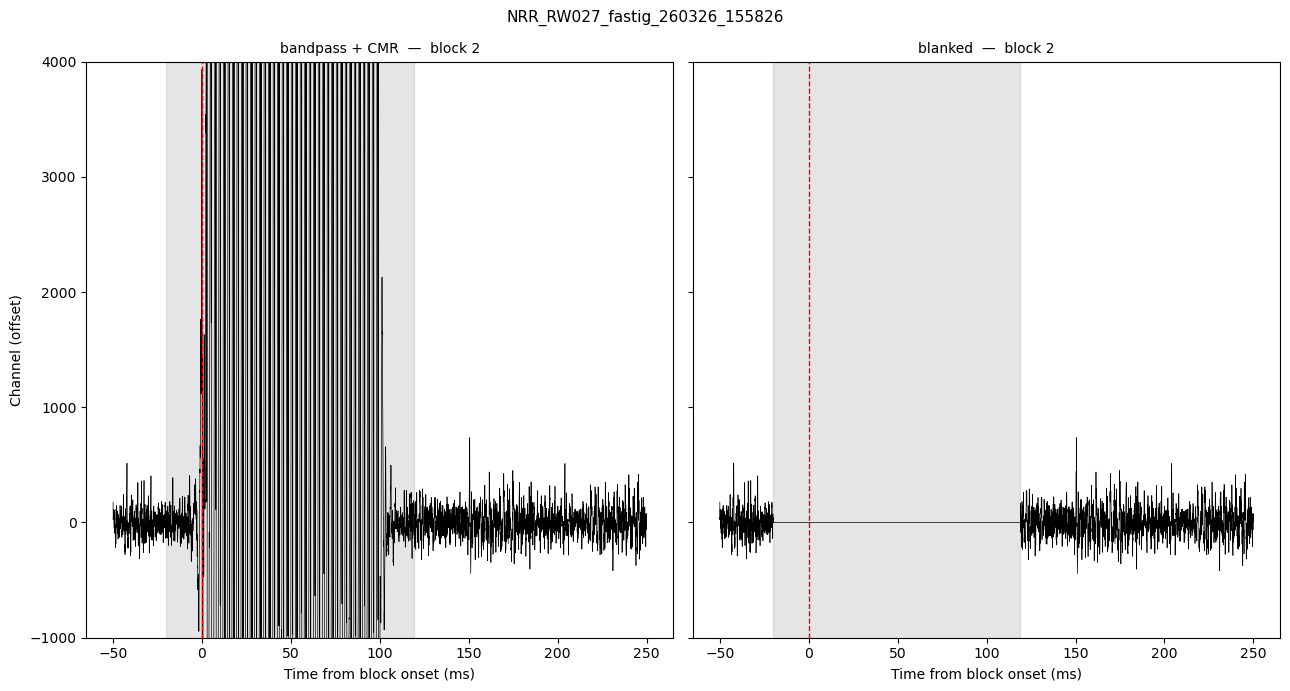

max|amplitude| inside blanked span: 0.000


In [64]:
if bb.shape[0] == 0:
    raise SystemExit("no stim blocks in this session")

k = min(2, bb.shape[0] - 1)          # third block, past any startup transient
center = int(bb[k, 0])
pre_ms, post_ms = 50.0, 250.0
chans = range(32, 33, 1)
spacing = 600.0

s0 = max(0, int(center - pre_ms * fs / 1000.0))
s1 = min(rec_blanked.get_num_samples(), int(center + post_ms * fs / 1000.0))
t = (np.arange(s0, s1) - center) * 1000.0 / fs

fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
for ax, rec, label in zip(axes, [rec_cmr, rec_blanked], ["bandpass + CMR", "blanked"]):
    tr = rec.get_traces(start_frame=s0, end_frame=s1)
    for row, ch in enumerate(chans):
        ax.plot(t, tr[:, ch] + row * spacing, lw=0.5, color="k")
    ax.axvline(0, color="r", ls="--", lw=1.0)
    ax.axvspan(-ARTRMV_MS_BEFORE,
               (bb[k, 1] - bb[k, 0]) * 1000.0 / fs + ARTRMV_TAIL_MS,
               color="grey", alpha=0.2)
    ax.set_title(f"{label}  —  block {k}", fontsize=10)
    ax.set_xlabel("Time from block onset (ms)")
axes[0].set_ylabel("Channel (offset)")
axes[0].set_ylim([-1000, 4000])
fig.suptitle(sess.name, fontsize=11)
fig.tight_layout()
plt.show()

# Blanked span should be exactly zero
chk = rec_blanked.get_traces(start_frame=int(bb[k, 0]), end_frame=int(bb[k, 1]))
print(f"max|amplitude| inside blanked span: {np.abs(chk).max():.3f}")

In [ ]:
SKIP_SESSIONS = {0, 1, 2}  # 0-indexed

SESSIONS_TO_SORT = [s.name for i, s in enumerate(sess_folders) if i not in SKIP_SESSIONS]

for i, sess in enumerate(tqdm(sess_folders, desc="Processing sessions")):
    # Skip if stated
    if i in SKIP_SESSIONS:
        tqdm.write(f"[{sess.name}] skipping (index {i}, manually excluded)")
        continue
    
    # Skip if exists
    stim_npz_path = NPRW_AUX_DATA / f"{sess.name}_Intan_streams" / "stim_stream.npz"
    if stim_npz_path.exists():
        loaded = np.load(stim_npz_path, allow_pickle=True)
        stim_arrays = {k: loaded[k] for k in loaded.files if k != "meta"}
    else:
        stim_arrays = rcp.extract_stim_npz(
            sess=sess, out_dir=NPRW_AUX_DATA,
            stim_stream_name=STIM_STREAM,
            chanmap_perm=intan_probe_mapping,
        )

    # Skip if exists
    sess_save_path = BLANKED_DIR / sess.name
    if sess_save_path.exists():
        tqdm.write(f"[{sess.name}] already saved, skipping")
        continue
    
    tqdm.write(f"[{sess.name}] loading, filtering, blanking")
    rec_raw = se.read_split_intan_files(sess, mode="concatenate", stream_name=INTAN_STREAM, use_names_as_ids=True)
    rec_raw = rec_raw.set_probe(nprw_probe)
    rec_raw = rcp.reorder_recording_to_geometry(rec_raw, intan_probe_mapping)
    
    rec_raw = spre.unsigned_to_signed(rec_raw)
    rec_bp = spre.bandpass_filter(rec_raw, freq_min=float(PARAMS.highpass_hz), freq_max=float(PARAMS.lowpass_hz), dtype="float32") # need float32 for filter
    rec_cmr = spre.common_reference(rec_bp, reference="local", operator="median", local_radius=RADII)
    rec_blanked = blank_session(rec_cmr, stim_arrays, fs, ARTRMV_MS_BEFORE, ARTRMV_TAIL_MS)

    # Save to disk per session
    rec_blanked_saved = rec_blanked.save(folder=sess_save_path, overwrite=True)
    tqdm.write(f"  saved {sess.name}: {rec_blanked_saved.get_total_duration():.1f}s, "
               f"{stim_arrays['block_bounds_samples'].shape[0]} stim blocks blanked")

    del rec_raw, rec_bp, rec_cmr, rec_blanked, rec_blanked_saved, stim_arrays
    gc.collect()

# Reload and sort concatenated

In [26]:
CONCAT_CKPT = OUT_BASE / "checkpoints" / "sorting_results" / f'NPRW_concat'
CONCAT_CKPT.mkdir(parents=True, exist_ok=True)

In [42]:
# Reload the recordings and concatenate
per_session_recs = []
for name in tqdm(SESSIONS_TO_SORT, desc="Reloading blanked sessions"):
    path = BLANKED_DIR / name
    if not path.exists():
        raise FileNotFoundError(f"{name} not blanked yet")
    per_session_recs.append(si.load(path))

rec_concat = si.concatenate_recordings(per_session_recs)
session_boundaries = np.concatenate([[0], np.cumsum([r.get_num_samples() for r in per_session_recs])])
sess_names = SESSIONS_TO_SORT

with open(CONCAT_CKPT / "session_index.pkl", "wb") as f:
    pickle.dump({"session_boundaries": session_boundaries, "sess_names": sess_names}, f)
    

Reloading blanked sessions: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 19/19 [00:02<00:00,  8.22it/s]


In [28]:
DRIFT_CKPT = OUT_BASE / "checkpoints" / "NPRW_drift"
# Motion estimation on the full concatenated recording
motion, motion_info = spre.compute_motion(rec_concat, preset="dredge", folder=DRIFT_CKPT, output_motion_info=True, overwrite=True)
with open(CONCAT_CKPT / "motion_info.pkl", "wb") as f:
    pickle.dump(motion_info, f)

interpolated_recording = interpolate_motion(recording=rec_concat, motion=motion_info['motion'],border_mode="force_extrapolate")

# Save the motion corrected recording
saved_rec_path = CONCAT_CKPT / "rec_corrected_saved"
interpolated_recording_i16 = spre.astype(interpolated_recording, dtype="int16")
rec_corrected_saved = interpolated_recording_i16.save(folder=saved_rec_path, overwrite=True)
print(rec_corrected_saved)

noise_level (workers: 12 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

detect and localize (workers: 12 processes fork):   0%|          | 0/753 [00:00<?, ?it/s]

Cross correlation:   0%|          | 0/3 [00:00<?, ?it/s]

Solve:   0%|          | 0/2 [00:00<?, ?it/s]

write_binary_recording 
engine=process - n_jobs=12 - samples_per_chunk=120,000 - chunk_memory=29.30 MiB - total_memory=351.56 MiB - chunk_duration=4.00s


write_binary_recording (workers: 12 processes fork):   0%|          | 0/753 [00:00<?, ?it/s]

BinaryFolderRecording: 128 channels - 30.0kHz - 1 segments - 90,310,912 samples 
                       3,010.36s (50.17 minutes) - int16 dtype - 21.53 GiB


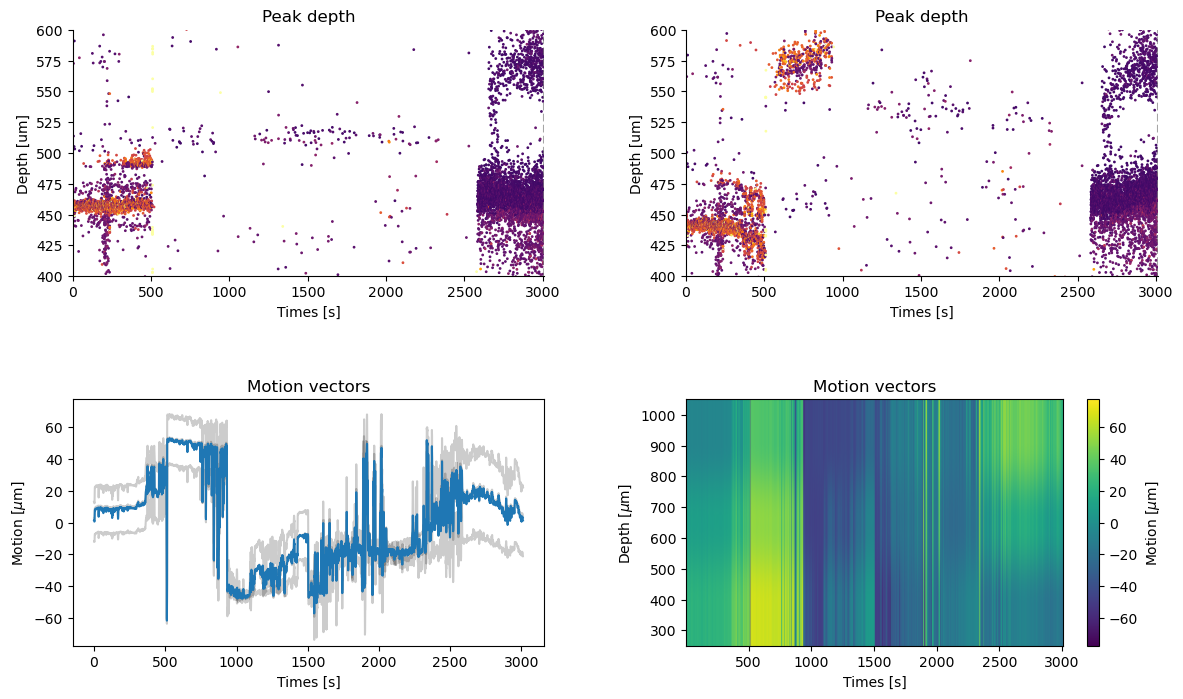

In [29]:
# Plot motion info
%matplotlib inline
fig = plt.figure(figsize=(14, 8))
plot_motion_info(
    motion_info, rec_concat,
    figure=fig,
    depth_lim=(400, 600),
    color_amplitude=True,
    amplitude_cmap="inferno",
    scatter_decimate=10,
)

In [30]:
# Reload saved files
saved_rec_path = CONCAT_CKPT / "rec_corrected_saved"
interpolated_recording = si.load(saved_rec_path)

with open(CONCAT_CKPT / "session_index.pkl", "rb") as f:
    session_index = pickle.load(f)
session_boundaries = session_index["session_boundaries"]
sess_names = session_index["sess_names"]

# Sort

In [31]:
# Kilosort4
sorting = ss.run_sorter(
    sorter_name="kilosort4",
    recording=interpolated_recording,
    folder=CONCAT_CKPT / "folder_KS4",
    remove_existing_folder=True,
    do_correction=False,
)
sorting = scur.remove_duplicated_spikes(sorting)
sorting = scur.remove_excess_spikes(sorting, interpolated_recording)
sorting = scur.remove_redundant_units(sorting, align=False, remove_strategy="max_spikes")
sorting.save(folder=CONCAT_CKPT / "sorting_curated", overwrite=True)

# Reload
sorting = si.load(CONCAT_CKPT / "sorting_curated")

folder = CONCAT_CKPT / "analyzer_pre_slay"
if folder.exists():
    shutil.rmtree(folder, ignore_errors=True)
    subprocess.run(["rm", "-rf", str(folder)], check=True)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [02:04<00:00, 124.30s/it]
/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/spikeinterface/core/basesorting.py:384: UserWarning: The registered recording will not be persistent on disk, but only available in memory
  warnings.warn("The registered recording will not be persistent on disk, but only available in memory")


In [32]:
sorting

NumpyFolder (NumpyFolderSorting): 254 units - 1 segments - 30.0kHz

In [33]:
# Phy export: post-curation, pre-SLAY
analyzer_precuration = si.create_sorting_analyzer(
    sorting, interpolated_recording,
    format="binary_folder",
    folder=CONCAT_CKPT / "analyzer_pre_slay",
    overwrite=True,
)
analyzer_precuration.compute(
    ["random_spikes", "waveforms", "templates", "noise_levels", "spike_amplitudes", "unit_locations", "quality_metrics"],
    extension_params={
        "quality_metrics": {"metric_names": ["snr", "firing_rate", "rp_violation"],
            "metric_params": {"rp_violation": {"refractory_period_ms": 0.5}},},
    },
)

export_to_phy(
    analyzer_precuration,
    output_folder=CONCAT_CKPT / "phy_pre_slay",
    remove_if_exists=True,
)
print(f"Phy export (pre-SLAY) -> {CONCAT_CKPT / 'phy_pre_slay'}")

estimate_sparsity (workers: 12 processes fork):   0%|          | 0/753 [00:00<?, ?it/s]

compute_waveforms (workers: 12 processes fork):   0%|          | 0/753 [00:00<?, ?it/s]

noise_level (workers: 12 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

Compute : spike_amplitudes (workers: 12 processes fork):   0%|          | 0/753 [00:00<?, ?it/s]

write_binary_recording (workers: 12 processes fork):   0%|          | 0/753 [00:00<?, ?it/s]

/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/spikeinterface/postprocessing/template_similarity.py:345: NumbaTypeSafetyWarning: unsafe cast from uint64 to int64. Precision may be lost.
  overlapping_ids = overlapping_j_list[i]


Fitting PCA:   0%|          | 0/254 [00:00<?, ?it/s]

Projecting waveforms:   0%|          | 0/254 [00:00<?, ?it/s]

extract PCs (workers: 12 processes fork):   0%|          | 0/753 [00:00<?, ?it/s]

Run:
phy template-gui  /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Nike/20260326_NRR_RW027_fastig/results/checkpoints/sorting_results/NPRW_concat/phy_pre_slay/params.py
Phy export (pre-SLAY) -> /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Nike/20260326_NRR_RW027_fastig/results/checkpoints/sorting_results/NPRW_concat/phy_pre_slay


# Save to Cal_ files

In [34]:
from spikeinterface import load_sorting_analyzer

interpolated_recording = si.load(CONCAT_CKPT / "rec_corrected_saved")
sorting = si.load(CONCAT_CKPT / "sorting_curated")
analyzer_precuration = load_sorting_analyzer(CONCAT_CKPT / "analyzer_pre_slay")

print(analyzer_precuration)

SortingAnalyzer: 128 channels - 254 units - 1 segments - binary_folder - sparse - has recording
Loaded 9 extensions: random_spikes, waveforms, noise_levels, unit_locations, quality_metrics, templates, spike_amplitudes, template_similarity, principal_components


In [35]:
analyzer_precuration

SortingAnalyzer: 128 channels - 254 units - 1 segments - binary_folder - sparse - has recording
Loaded 9 extensions: random_spikes, waveforms, noise_levels, unit_locations, quality_metrics, templates, spike_amplitudes, template_similarity, principal_components

In [36]:
# Split per session and save spike trains
per_session_trains = {}  # sess_name -> {unit_id_str: samples relative to session start}

for i, sess_name in enumerate(tqdm(sess_names, desc="Saving spike trains")):
    t_start = int(session_boundaries[i])
    t_end = int(session_boundaries[i + 1])

    spike_trains = {}
    for uid in analyzer_precuration.unit_ids:
        st = analyzer_precuration.sorting.get_unit_spike_train(uid, segment_index=0)
        mask = (st >= t_start) & (st < t_end)
        spike_trains[str(uid)] = st[mask] - t_start

    per_session_trains[sess_name] = spike_trains  # keep for Cal stitching

    total = sum(len(v) for v in spike_trains.values())
    tqdm.write(f"[{sess_name}] total_spikes={total}")

    out_path = OUT_BASE / "checkpoints" / "sorting_results" / sess_name / "NPRW"
    out_path.mkdir(parents=True, exist_ok=True)

    fs = float(analyzer_precuration.sorting.get_sampling_frequency())
    savemat(out_path / "spike_trains.mat",
            {f"unit_{k}": v for k, v in spike_trains.items()} | {"fs": fs})
    np.savez(out_path / "spike_trains.npz",
             **{f"unit_{k}": v for k, v in spike_trains.items()}, fs=fs)

Saving spike trains:   0%|                                                                                                                                                 | 0/19 [00:01<?, ?it/s]

[NRR_RW027_fastig_260326_151239] total_spikes=1970229


Saving spike trains:   5%|███████▏                                                                                                                                 | 1/19 [00:01<00:34,  1.92s/it]

[NRR_RW027_fastig_260326_154530] total_spikes=1332913


Saving spike trains:  11%|██████████████▍                                                                                                                          | 2/19 [00:02<00:16,  1.00it/s]

[NRR_RW027_fastig_260326_155408] total_spikes=889899


... (15 outputs left out)

[NRR_RW027_fastig_260326_164345] total_spikes=148957
[NRR_RW027_fastig_260326_164510] total_spikes=129084


Saving spike trains:  95%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▊       | 18/19 [00:05<00:00,  7.03it/s]

[NRR_RW027_fastig_260326_164636] total_spikes=186649
[NRR_RW027_fastig_260326_164816] total_spikes=199270


Saving spike trains: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 19/19 [00:05<00:00,  3.64it/s]


In [37]:
from spikeinterface import load_sorting_analyzer

CONCAT_CKPT = OUT_BASE / "checkpoints" / "sorting_results" / "NPRW_concat"
STITCH_SUFFIX = "_stitched_all_sess"

with open(CONCAT_CKPT / "session_index.pkl", "rb") as f:
    session_index = pickle.load(f)
session_boundaries = session_index["session_boundaries"]
sess_names = session_index["sess_names"]

analyzer_precuration = load_sorting_analyzer(CONCAT_CKPT / "analyzer_pre_slay")
sorting_final = analyzer_precuration.sorting

per_session_trains = {}
for i, name in enumerate(sess_names):
    t0, t1 = int(session_boundaries[i]), int(session_boundaries[i + 1])
    per_session_trains[name] = {
        str(uid): (lambda st: st[(st >= t0) & (st < t1)] - t0)(
            sorting_final.get_unit_spike_train(uid, segment_index=0))
        for uid in sorting_final.unit_ids
    }

In [38]:
STITCH_SUFFIX = "_stitched_all_sess"
# Add to _Cal files
import h5py

# Stitch unit spike trains and extracted stim into copies of the Cal files.
# Positions written are indices *within* Intan_idx, so downstream code can divide by fs
# directly and compare against kinematics in the same file. Originals never modified.

CAL_ROOT = Path(str(PARAMS.data_root)) / Path(str(PARAMS.location)) / "Calibrated"

# Session i (0-based) -> IntanFile_{i+1}. Override this dict if that mapping doesn't hold.
all_sess_names = [s.name for s in rcp.list_intan_sessions(INTAN_ROOT)]
CAL_DIR_FOR_SESSION = {name: CAL_ROOT / f"IntanFile_{i + 1}"
                       for i, name in enumerate(all_sess_names)}

STIM_PREFIX = "stim_"
SAMPLE_KEY_HINTS = ("sample", "idx", "index")  # keys that hold Intan sample indices

_MATLAB_CLASS = {
    "int64": ("int64", 8), "int32": ("int32", 4), "int16": ("int16", 2),
    "uint64": ("uint64", 8), "uint32": ("uint32", 4), "uint16": ("uint16", 2),
    "uint8": ("uint8", 1), "float64": ("double", None), "float32": ("single", None),
}


def write_matlab_array(group, name, arr):
    """Write a numeric array as a MATLAB-readable dataset. Returns True if written."""
    arr = np.asarray(arr)
    if arr.dtype.kind in "OUS":
        return False  # skip strings and object arrays
    if arr.dtype == np.bool_:
        arr, cls, decode = arr.astype(np.uint8), "logical", 1
    else:
        cls, decode = _MATLAB_CLASS.get(arr.dtype.name, ("double", None))
        if cls == "double" and arr.dtype.name not in _MATLAB_CLASS:
            arr = arr.astype(np.float64)

    if arr.ndim == 0:
        arr = arr.reshape(1, 1)
    elif arr.ndim == 1:
        arr = arr.reshape(1, -1)  # -> N x 1 in MATLAB
    else:
        arr = arr.T  # h5py is transposed relative to MATLAB

    if name in group:
        del group[name]
    dset = group.create_dataset(name, data=np.ascontiguousarray(arr))
    dset.attrs["MATLAB_class"] = np.bytes_(cls)
    if decode is not None:
        dset.attrs["MATLAB_int_decode"] = np.int64(decode)
    return True


def align_unit_to_intan(unit_samples, intan_idx):
    """Map a unit's condition spike trains in Intan time onto BR time using Intan_idx"""
    _, idx_in_rec, _ = np.intersect1d(intan_idx, np.asarray(unit_samples, np.int64), return_indices=True)
    return np.sort(idx_in_rec)


def samples_to_intan_pos(samples, intan_idx):
    """Map session-relative Intan samples onto positions within Intan_idx.

    Unlike the unit path, stim block edges need not themselves appear in Intan_idx,
    so this snaps to the nearest position. Samples outside the Cal file's span map
    to -1. Shape is preserved, so an (n_blocks, 2) bounds matrix stays (n_blocks, 2).
    """
    samples = np.asarray(samples, np.int64)
    intan_idx = np.asarray(intan_idx, np.int64)
    order = np.argsort(intan_idx, kind="stable")
    ordered = intan_idx[order]

    ins = np.searchsorted(ordered, samples.ravel())
    ins = np.clip(ins, 1, ordered.size - 1)
    left, right = ordered[ins - 1], ordered[ins]
    nearest = np.where(np.abs(samples.ravel() - left) <= np.abs(right - samples.ravel()),
                       ins - 1, ins)
    pos = order[nearest].astype(np.int64)
    pos[(samples.ravel() < ordered[0]) | (samples.ravel() > ordered[-1])] = -1
    return pos.reshape(samples.shape)


def load_stim_arrays(sess_name):
    """Load a session's extracted stim npz, same path the preprocessing loop writes."""
    p = NPRW_AUX_DATA / f"{sess_name}_Intan_streams" / "stim_stream.npz"
    if not p.exists():
        return None
    with np.load(p, allow_pickle=True) as z:
        return {k: z[k] for k in z.files if k != "meta"}


# Arrays holding Intan sample indices — these get a _pos twin mapped into Intan_idx
STIM_SAMPLE_KEYS = ("block_bounds_samples", "trigger_pairs")
# Arrays worth carrying over as-is (no position mapping — not sample indices)
STIM_PLAIN_KEYS = ("active_channels", "active_channels_0based", "pulse_sizes")


def build_stim_fields(stim_arrays, intan_idx, prefix=STIM_PREFIX):
    """Flatten a stim npz into MATLAB-writable fields.

    Sample-index arrays are written as-is under <prefix><key> and again as
    <prefix><key>_pos, mapped into positions within Intan_idx so they line up
    with the unit_* fields and the kinematics. Events outside this Cal file's
    span map to -1. Non-index arrays are written as-is only.
    """
    fields = {}

    for key in STIM_SAMPLE_KEYS:
        if key not in stim_arrays:
            continue
        arr = np.asarray(stim_arrays[key])
        if arr.dtype.kind not in "iu":
            continue
        fields[f"{prefix}{key}"] = arr
        fields[f"{prefix}{key}_pos"] = samples_to_intan_pos(arr, intan_idx)

    for key in STIM_PLAIN_KEYS:
        if key not in stim_arrays:
            continue
        arr = np.asarray(stim_arrays[key])
        if arr.dtype.kind in "OUS":
            continue
        fields[f"{prefix}{key}"] = arr

    return fields


def stitch_cal_file(cal_path, pos_by_uid, extra_fields=None, suffix="_stitched"):
    """Copy a v7.3 Cal file and add unit positions plus any extra numeric fields."""
    out_path = cal_path.with_name(cal_path.stem + suffix + cal_path.suffix)
    shutil.copyfile(str(cal_path), str(out_path))

    vlen = h5py.special_dtype(vlen=np.uint8)
    with h5py.File(str(out_path), "r+") as f:
        data = f["Data"]
        if "MATLAB_fields" in data.attrs:
            existing = [bytes(x).decode("ascii") for x in data.attrs["MATLAB_fields"]]
        else:
            existing = list(data.keys())

        n_units, n_extra, new_names = 0, 0, []

        for uid, pos in pos_by_uid.items():
            if pos is None or pos.size == 0:
                continue
            name = f"unit_{uid}"
            if write_matlab_array(data, name, np.asarray(pos, np.int64)):
                if name not in existing and name not in new_names:
                    new_names.append(name)
                n_units += 1

        for name, arr in (extra_fields or {}).items():
            if write_matlab_array(data, name, arr):
                if name not in existing and name not in new_names:
                    new_names.append(name)
                n_extra += 1

        all_fields = existing + new_names
        field_arr = np.empty(len(all_fields), dtype=vlen)
        for i, nm in enumerate(all_fields):
            field_arr[i] = np.frombuffer(nm.encode("ascii"), dtype=np.uint8)
        if "MATLAB_fields" in data.attrs:
            del data.attrs["MATLAB_fields"]
        data.attrs.create("MATLAB_fields", field_arr)

    return out_path, n_units, n_extra

In [39]:
BAD_STEMS = ("_stitched", "_old")

for i, sess_name in enumerate(tqdm(sess_names[9:], desc="Stitching Cal files")):
    cal_dir = CAL_DIR_FOR_SESSION.get(sess_name)
    if cal_dir is None or not cal_dir.exists():
        tqdm.write(f"[{sess_name}] no Cal dir, skipping")
        continue

    # Prefer *_Cal_stim*.mat if present, otherwise fall back to *_Cal.mat.
    cal_files = sorted(
        p for p in cal_dir.glob("*_Cal_stim*.mat")
        if not p.name.startswith("._")
        and not any(t in p.stem for t in BAD_STEMS)
    )

    if not cal_files:
        cal_files = sorted(
            p for p in cal_dir.glob("*_Cal.mat")
            if not p.name.startswith("._")
            and not any(t in p.stem for t in BAD_STEMS)
        )

    if not cal_files:
        tqdm.write(f"[{sess_name}] no Cal or Cal_stim files in {cal_dir.name}, skipping")
        continue

    trains = per_session_trains[sess_name]
    stim_arrays = load_stim_arrays(sess_name)
    if stim_arrays is None:
        tqdm.write(f"[{sess_name}] no stim npz, stitching units only")

    for cal_path in cal_files:
        with h5py.File(cal_path, "r") as f:
            intan_idx = np.asarray(f["Data"]["Intan_idx"]).ravel().astype(np.int64)

        # Mapping to BR time
        pos_by_uid = {int(uid): align_unit_to_intan(st, intan_idx)
                      for uid, st in trains.items()}
        n_nonempty = sum(1 for v in pos_by_uid.values() if v.size)
        stim_fields = build_stim_fields(stim_arrays, intan_idx) if stim_arrays else None

        in_span = ""
        if stim_fields is not None and f"{STIM_PREFIX}block_bounds_samples_pos" in stim_fields:
            bb = stim_fields[f"{STIM_PREFIX}block_bounds_samples_pos"]
            n_in = int(np.sum(np.all(bb >= 0, axis=1))) if bb.ndim == 2 else int(np.sum(bb >= 0))
            in_span = f", {n_in}/{bb.shape[0]} stim blocks in span"

        out_path, n_units, n_extra = stitch_cal_file(cal_path, pos_by_uid, stim_fields,
                                                     suffix=STITCH_SUFFIX)
        tqdm.write(f"[{sess_name}] {cal_path.name}: {n_units} units "
                   f"({n_nonempty} with spikes in span), {n_extra} stim fields{in_span} "
                   f"-> {out_path.name}")

print("Done stitching.")

Stitching Cal files:   0%|                                                                                                                                                 | 0/10 [00:00<?, ?it/s]

Stitching Cal files:  10%|█████████████▋                                                                                                                           | 1/10 [01:17<11:36, 77.35s/it]

[NRR_RW027_fastig_260326_162251] NRR_RW027_013_Cal.mat: 212 units (212 with spikes in span), 7 stim fields, 127/128 stim blocks in span -> NRR_RW027_013_Cal_stitched_all_sess.mat


Stitching Cal files:  20%|███████████████████████████▍                                                                                                             | 2/10 [01:53<07:06, 53.33s/it]

[NRR_RW027_fastig_260326_162935] NRR_RW027_014_Cal.mat: 209 units (209 with spikes in span), 7 stim fields, 0/1 stim blocks in span -> NRR_RW027_014_Cal_stitched_all_sess.mat


Stitching Cal files:  30%|█████████████████████████████████████████                                                                                                | 3/10 [02:00<03:43, 31.90s/it]

... (11 outputs left out)

Stitching Cal files:  90%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▎             | 9/10 [02:44<00:09,  9.03s/it]

[NRR_RW027_fastig_260326_164636] NRR_RW027_021_Cal.mat: 146 units (146 with spikes in span), 7 stim fields, 11/12 stim blocks in span -> NRR_RW027_021_Cal_stitched_all_sess.mat


Stitching Cal files: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [02:52<00:00, 17.23s/it]

[NRR_RW027_fastig_260326_164816] NRR_RW027_022_Cal.mat: 152 units (152 with spikes in span), 7 stim fields, 0/0 stim blocks in span -> NRR_RW027_022_Cal_stitched_all_sess.mat
Done stitching.


# Sort only one condition (random delay, adaptation)

In [31]:
# BL_closed_loop_STIM_003_250528_143802, BL_closed_loop_STIM_003_250528_150847
sess_name = 'BL_closed_loop_STIM_003_250528_143802'
DRIFT_CKPT_SINGLE = OUT_BASE / "checkpoints" / f'NPRW_drift_{sess_name}_blanking'
SORT_CKPT = OUT_BASE / "checkpoints" / "sorting_results" / f'{sess_name}_blanking'
DRIFT_CKPT_SINGLE.mkdir(parents=True, exist_ok=True)
SORT_CKPT.mkdir(parents=True, exist_ok=True)

In [32]:
sess_save_path = BLANKED_DIR / sess_name
rec = si.load(sess_save_path)

# Motion estimation on the single recording
motion, motion_info = spre.compute_motion(rec, preset="dredge", folder=DRIFT_CKPT_SINGLE, output_motion_info=True, overwrite=True)
with open(SORT_CKPT / "motion_info.pkl", "wb") as f:
    pickle.dump(motion_info, f)
interpolated_recording = interpolate_motion(recording=rec, motion=motion_info['motion'],border_mode="force_extrapolate")

# Save the motion corrected recording
saved_rec_path = SORT_CKPT / "rec_corrected_saved"
interpolated_recording_i16 = spre.astype(interpolated_recording, dtype="int16")
rec_corrected_saved = interpolated_recording_i16.save(folder=saved_rec_path, overwrite=True)
print(rec_corrected_saved)

noise_level (workers: 12 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

detect and localize (workers: 12 processes fork):   0%|          | 0/57 [00:00<?, ?it/s]

Cross correlation:   0%|          | 0/3 [00:00<?, ?it/s]

Solve:   0%|          | 0/2 [00:00<?, ?it/s]

write_binary_recording 
engine=process - n_jobs=12 - samples_per_chunk=120,000 - chunk_memory=29.30 MiB - total_memory=351.56 MiB - chunk_duration=4.00s


write_binary_recording (workers: 12 processes fork):   0%|          | 0/57 [00:00<?, ?it/s]

BinaryFolderRecording: 128 channels - 30.0kHz - 1 segments - 6,769,408 samples 
                       225.65s (3.76 minutes) - int16 dtype - 1.61 GiB


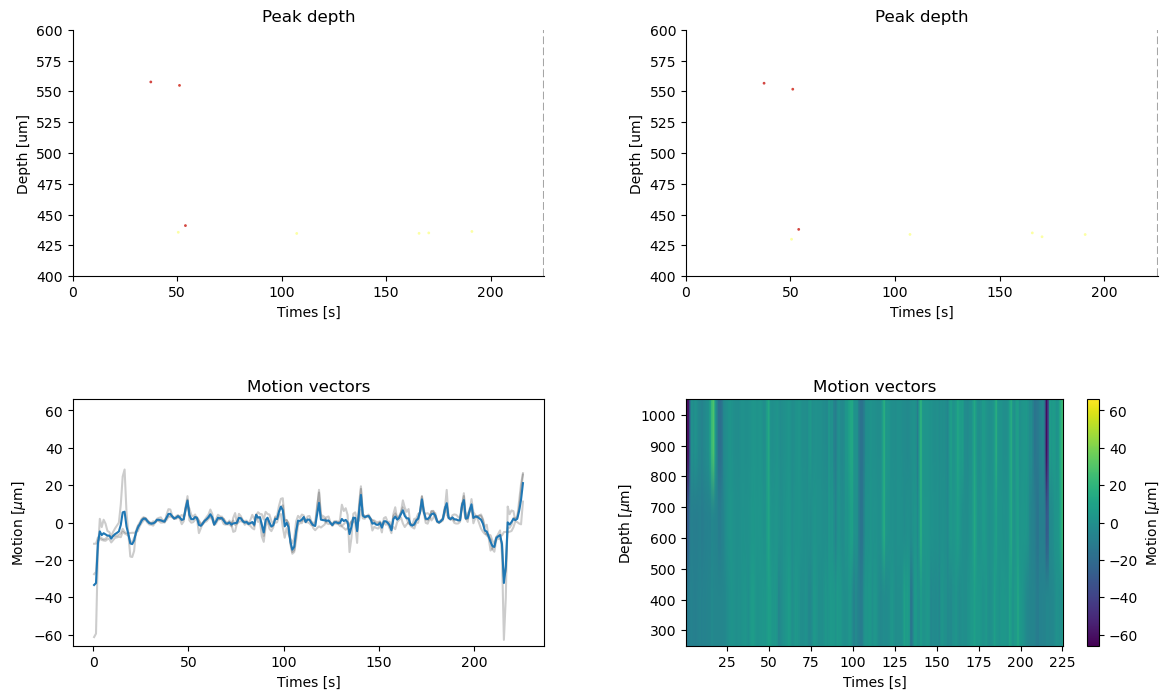

In [33]:
# Plot motion info
%matplotlib inline
fig = plt.figure(figsize=(14, 8))
plot_motion_info(
    motion_info, rec,
    figure=fig,
    depth_lim=(400, 600),
    color_amplitude=True,
    amplitude_cmap="inferno",
    scatter_decimate=10,
)

In [34]:
# Reload saved files
saved_rec_path = SORT_CKPT / "rec_corrected_saved"
interpolated_recording = si.load(saved_rec_path)

In [35]:
# Kilosort4
sorting = ss.run_sorter(
    sorter_name="kilosort4",
    recording=interpolated_recording,
    folder=SORT_CKPT / "folder_KS4",
    remove_existing_folder=True,
    do_correction=False,
)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:07<00:00,  7.14s/it]


In [36]:
# Sort
sorting = scur.remove_duplicated_spikes(sorting)
sorting = scur.remove_excess_spikes(sorting, interpolated_recording)
sorting = scur.remove_redundant_units(sorting, align=False, remove_strategy="max_spikes")
sorting.save(folder=SORT_CKPT / "sorting_curated", overwrite=True)

/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/spikeinterface/core/basesorting.py:384: UserWarning: The registered recording will not be persistent on disk, but only available in memory
  warnings.warn("The registered recording will not be persistent on disk, but only available in memory")


NumpyFolder (NumpyFolderSorting): 171 units - 1 segments - 30.0kHz

In [37]:
# Reload
sorting = si.load(SORT_CKPT / "sorting_curated")

folder = SORT_CKPT / "analyzer_pre_slay"
if folder.exists():
    shutil.rmtree(folder, ignore_errors=True)
    subprocess.run(["rm", "-rf", str(folder)], check=True)
# Phy export: post-curation, pre-SLAY
analyzer_precuration = si.create_sorting_analyzer(
    sorting, interpolated_recording,
    format="binary_folder",
    folder=SORT_CKPT / "analyzer_pre_slay",
    overwrite=True,
)

analyzer_precuration.compute(
    ["random_spikes", "waveforms", "templates", "noise_levels", "spike_amplitudes", "unit_locations", "quality_metrics"],
    extension_params={
        "quality_metrics": {"metric_names": ["snr", "firing_rate", "rp_violation"],
            "metric_params": {"rp_violation": {"refractory_period_ms": 0.5}},},
    },
)

export_to_phy(
    analyzer_precuration,
    output_folder=SORT_CKPT / "phy_pre_slay",
    remove_if_exists=True,
)
print(f"Phy export (pre-SLAY) -> {SORT_CKPT / 'phy_pre_slay'}")

estimate_sparsity (workers: 12 processes fork):   0%|          | 0/57 [00:00<?, ?it/s]

compute_waveforms (workers: 12 processes fork):   0%|          | 0/57 [00:00<?, ?it/s]

noise_level (workers: 12 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

Compute : spike_amplitudes (workers: 12 processes fork):   0%|          | 0/57 [00:00<?, ?it/s]

write_binary_recording (workers: 12 processes fork):   0%|          | 0/57 [00:00<?, ?it/s]

Fitting PCA:   0%|          | 0/171 [00:00<?, ?it/s]

Projecting waveforms:   0%|          | 0/171 [00:00<?, ?it/s]

extract PCs (workers: 12 processes fork):   0%|          | 0/57 [00:00<?, ?it/s]

Run:
phy template-gui  /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/sorting_results/BL_closed_loop_STIM_003_250528_143802_blanking/phy_pre_slay/params.py
Phy export (pre-SLAY) -> /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/sorting_results/BL_closed_loop_STIM_003_250528_143802_blanking/phy_pre_slay


In [38]:
qm_sess = analyzer_precuration.get_extension("quality_metrics").get_data()
passing = qm_sess[
    (qm_sess["firing_rate"] > 0.1) &
    (qm_sess["snr"] > 3.0) &
    (qm_sess["rp_contamination"] < 0.2)
].index

passing = passing.tolist()
print(f"[global QM] {len(passing)}/{len(qm_sess)} units pass SNR/FR/RP")

analyzer_filtered = analyzer_precuration.select_units(passing)
analyzer_filtered = analyzer_filtered.save_as(
    folder=SORT_CKPT / "analyzer_qm_filtered", format="binary_folder", 
)

[global QM] 75/171 units pass SNR/FR/RP


In [39]:
analyzer_filtered

SortingAnalyzer: 128 channels - 75 units - 1 segments - binary_folder - sparse - has recording
Loaded 9 extensions: random_spikes, waveforms, templates, noise_levels, unit_locations, quality_metrics, spike_amplitudes, template_similarity, principal_components

In [40]:
export_to_phy(
    analyzer_filtered,
    output_folder=SORT_CKPT / "phy_qm_filtered",
    remove_if_exists=True,
)
print(f"Phy export (QM filtered) -> {SORT_CKPT / 'phy_qm_filtered'}")

write_binary_recording (workers: 12 processes fork):   0%|          | 0/57 [00:00<?, ?it/s]

extract PCs (workers: 12 processes fork):   0%|          | 0/57 [00:00<?, ?it/s]

Run:
phy template-gui  /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/sorting_results/BL_closed_loop_STIM_003_250528_143802_blanking/phy_qm_filtered/params.py
Phy export (QM filtered) -> /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/sorting_results/BL_closed_loop_STIM_003_250528_143802_blanking/phy_qm_filtered


In [41]:
# SLAY
merge_groups = compute_merge_unit_groups(analyzer_filtered, preset="slay", resolve_graph=True)
merge_groups

[[np.int64(108), np.int64(140), np.int64(142)]]

In [42]:
if merge_groups is not None and len(merge_groups) > 0:
    analyzer_SLAy = analyzer_filtered.merge_units(merge_unit_groups=merge_groups)
    print(f"[concat] {analyzer_SLAy.sorting.get_num_units()} units after SLAY merge")
else:
    analyzer_SLAy = analyzer_filtered
    print(f"[concat] no merges found, {analyzer_SLAy.sorting.get_num_units()} units")    

[concat] 73 units after SLAY merge


In [44]:
analyzer_SLAy = analyzer_SLAy.save_as(
    folder=SORT_CKPT / "analyzer_SLAy", format="binary_folder"
)
export_to_phy(
    analyzer_SLAy,
    output_folder=SORT_CKPT / "phy_slay",
    remove_if_exists=True,
)
print(f"Phy export (post-SLAY) -> {SORT_CKPT / 'phy_slay'}")

write_binary_recording (workers: 12 processes fork):   0%|          | 0/57 [00:00<?, ?it/s]

extract PCs (workers: 12 processes fork):   0%|          | 0/57 [00:00<?, ?it/s]

Run:
phy template-gui  /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/sorting_results/BL_closed_loop_STIM_003_250528_143802_blanking/phy_slay/params.py
Phy export (post-SLAY) -> /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/sorting_results/BL_closed_loop_STIM_003_250528_143802_blanking/phy_slay


In [45]:
STITCH_SUFFIX = "_stitched_individual"

sorting_final = analyzer_SLAy.sorting
fs_sort = float(sorting_final.get_sampling_frequency())

spike_trains = {str(uid): sorting_final.get_unit_spike_train(uid, segment_index=0)
                for uid in sorting_final.unit_ids}
per_session_trains = {sess_name: spike_trains}
sess_names = [sess_name]

out_path = OUT_BASE / "checkpoints" / "sorting_results" / sess_name / "NPRW"
out_path.mkdir(parents=True, exist_ok=True)
savemat(out_path / "spike_trains_individual.mat",
        {f"unit_{k}": v for k, v in spike_trains.items()} | {"fs": fs_sort})
np.savez(out_path / "spike_trains_individual.npz",
         **{f"unit_{k}": v for k, v in spike_trains.items()}, fs=fs_sort)

print(f"[{sess_name}] {len(spike_trains)} units, "
      f"{sum(len(v) for v in spike_trains.values())} spikes")

[BL_closed_loop_STIM_003_250528_143802] 73 units, 284987 spikes


In [59]:
from spikeinterface import load_sorting_analyzer

sess_name = 'BL_closed_loop_STIM_003_250528_143802' # BL_closed_loop_STIM_003_250528_143802, BL_closed_loop_STIM_003_250528_150847
SORT_CKPT = OUT_BASE / "checkpoints" / "sorting_results" / f'{sess_name}_blanking'
STITCH_SUFFIX = "_stitched_individual"

analyzer_SLAy = load_sorting_analyzer(SORT_CKPT / "analyzer_SLAy")
sorting_final = analyzer_SLAy.sorting

spike_trains = {str(uid): sorting_final.get_unit_spike_train(uid, segment_index=0)
                for uid in sorting_final.unit_ids}
per_session_trains = {sess_name: spike_trains}
sess_names = [sess_name]

print(f"{len(spike_trains)} units, {sum(len(v) for v in spike_trains.values())} spikes")

73 units, 284987 spikes


In [60]:
for i, sess_name in enumerate(tqdm(sess_names, desc="Stitching Cal files")):
    cal_dir = CAL_DIR_FOR_SESSION.get(sess_name)
    if cal_dir is None or not cal_dir.exists():
        tqdm.write(f"[{sess_name}] no Cal dir, skipping")
        continue

    # Prefer *_Cal_stim*.mat if present, otherwise fall back to *_Cal*.mat.
    BAD_STEMS = ("_stitched", "_old")

    cal_files = sorted(
        p for p in cal_dir.glob("*_Cal_stim*.mat")
        if not p.name.startswith("._")
        and not any(t in p.stem for t in BAD_STEMS)
    )

    if not cal_files:
        cal_files = sorted(
            p for p in cal_dir.glob("*_Cal*.mat")
            if not p.name.startswith("._")
            and not any(t in p.stem for t in BAD_STEMS)
        )
    if not cal_files:
        tqdm.write(f"[{sess_name}] no Cal or Cal_stim files in {cal_dir.name}, skipping")
        continue

    trains = per_session_trains[sess_name]
    stim_arrays = load_stim_arrays(sess_name)
    if stim_arrays is None:
        tqdm.write(f"[{sess_name}] no stim npz, stitching units only")

    for cal_path in cal_files:
        print(cal_path)
        with h5py.File(cal_path, "r") as f:
            intan_idx = np.asarray(f["Data"]["Intan_idx"]).ravel().astype(np.int64)

        # Mapping to BR time
        pos_by_uid = {int(uid): align_unit_to_intan(st, intan_idx)
                      for uid, st in trains.items()}
        
        # Saving stim timing
        stim_fields = build_stim_fields(stim_arrays, intan_idx) if stim_arrays else None

        # how many stim blocks actually fall inside this Cal file's span
        in_span = ""
        if stim_fields is not None and f"{STIM_PREFIX}block_bounds_samples_pos" in stim_fields:
            bb = stim_fields[f"{STIM_PREFIX}block_bounds_samples_pos"]
            n_in = int(np.sum(np.all(bb >= 0, axis=1))) if bb.ndim == 2 else int(np.sum(bb >= 0))
            in_span = f", {n_in}/{bb.shape[0]} stim blocks in span"

        out_path, n_units, n_extra = stitch_cal_file(cal_path, pos_by_uid, stim_fields, suffix=STITCH_SUFFIX)
        tqdm.write(f"[{sess_name}] {cal_path.name}: {n_units} units, "
                   f"{n_extra} stim fields{in_span} -> {out_path.name}")

print("Done stitching.")

Stitching Cal files:   0%|                                                                                                                                                  | 0/1 [00:00<?, ?it/s]

/home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/Calibrated/IntanFile_3/BL_closed_loop_STIM_003_006_Cal_stim.mat


Stitching Cal files: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:25<00:00, 25.64s/it]

[BL_closed_loop_STIM_003_250528_143802] BL_closed_loop_STIM_003_006_Cal_stim.mat: 73 units, 6 stim fields, 75/75 stim blocks in span -> BL_closed_loop_STIM_003_006_Cal_stim_stitched_individual.mat
Done stitching.


# Bad units from concatenating first 5 files

In [ ]:
#merge_units censor_ms to 5 samples, to remove duplicate spikes
remove_unit_ids = [198, 41, 11, 28, 46, 106, 47, 62, 67, 73, 78, 82, 86, 124, 134, 137, 139, 156, 168, 169, 197]

# remove some units
# analyzer_clean = analyzer_final.remove_units(remove_unit_ids=remove_unit_ids, )
# analyzer_clean = analyzer_clean.save_as(folder=SORT_CKPT / "analyzer_blanking_cleaned", format="binary_folder")